# Event-attribution tutorial

This concise tutorial uses the `organizer_dominant` simulation to illustrate how CellVOCAL attributes a receiver response to plausible sender cells. The same analysis can be applied to the collective, contact-dependent, graded-paracrine, and developmental-switch inputs by changing `MODE`. Prepared H5AD files are read directly.

> Start Jupyter from the repository root. The training call is commented by default.

In [1]:
from base64 import b64encode
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "model").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import anndata as ad
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from IPython.utils.capture import capture_output

from model.train.config import CellVOCALConfig
from pipeline.analysis import CellVOCALAnalysis
from pipeline.cellvocal import run_cellvocal


In [2]:
DATA_ROOT = ROOT / "paper" / "data" / "event_attribution"
MODE = "organizer_dominant"

cfg = CellVOCALConfig()
cfg.train.device = "cuda:0" if torch.cuda.is_available() else "cpu"
cfg.train.checkpoint_dir = DATA_ROOT / "cellvocal" / MODE / "checkpoints"
cfg.eval.output_dir = DATA_ROOT / "cellvocal" / MODE / "results"
cfg.qc.normalize_per_spot = False
cfg.model.use_cell_annotation = False
cfg.graph.n_spatial_neighbors = 90
cfg.graph.ccc_event_budget_per_receiver = 72
cfg.graph.ccc_ligand_expr_quantile = 0.5
cfg.graph.ccc_receptor_expr_quantile = 0.5
cfg.train.time_prior_source = "rna_maturity"
cfg.train.w_ccc = 0.3
cfg.train.w_time = 0.5

## Train one communication mechanism

The LR prior identifies candidate modules, while the spatial graph determines which sender-receiver pairs are eligible. Inferred signalling influence is learned jointly with RNA velocity.

In [3]:
# adata = ad.read_h5ad(DATA_ROOT / "raw" / f"{MODE}.h5ad")
# edges = np.linspace(adata.obs["true_time"].min(), adata.obs["true_time"].max(), 6)
# adata.obs["clusters"] = np.digitize(adata.obs["true_time"], edges[1:-1]).astype(str)
# lr = adata.uns["ground_truth"]["lr_pairs"]
# lr_pairs = [{"interaction": f"{lig}_{rec}", "pathway": str(mod), "module_id": str(mod), "ligand": str(lig), "receptor": str(rec), "ligand_genes": [str(lig)], "receptor_genes": [str(rec)]} for lig, rec, mod in zip(lr["ligand_gene"], lr["receptor_gene"], lr["module_id"])]
# result = run_cellvocal(adata, config=cfg, lr_pairs=lr_pairs)

## Test event-attribution recovery

`organizer_dominant` is designed to concentrate influence on a small number of effective senders. The compact profile states that ground-truth property; top-ranked recall and precision lift quantify recovery without printing the 13,000-row ROC table. LR totals then show whether recovery is spread evenly across the four simulated modules.

,value
true positive events,5220.000
mean effective senders per LR,1.739
mean top-sender share (%),68.644
mean sender–receiver distance,0.046


,top_percent,recall,precision_lift
0,1.0,0.097,9.870
1,5.0,0.383,7.768
2,10.0,0.559,5.671


,LR module,event_influence,share (%)
0,G0140->G0133,715.1,25.3
1,G0152->G0092,712.5,25.2
2,G0302->G0237,704.3,24.9
3,G0344->G0340,699.6,24.7



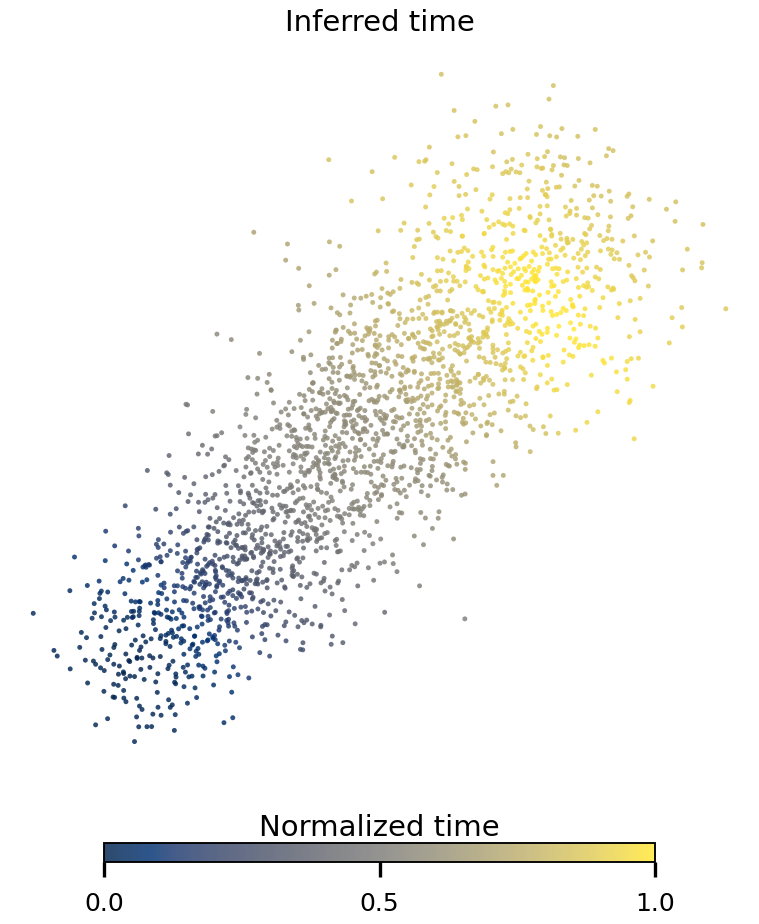
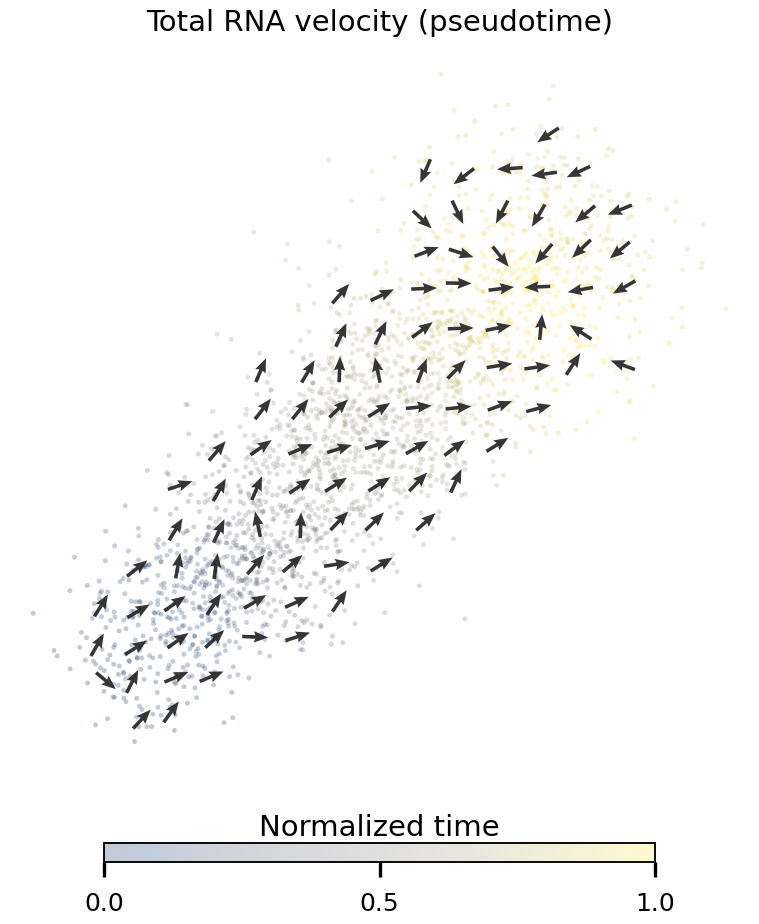
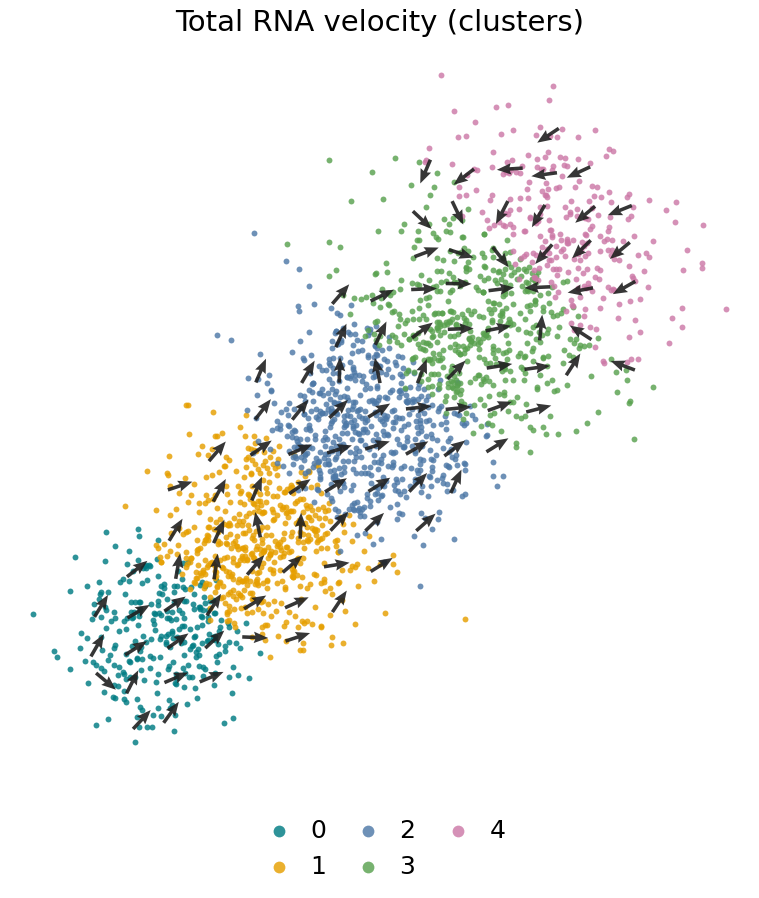

In [4]:
analysis = CellVOCALAnalysis.from_h5ad(cfg.eval.output_dir / "out.h5ad", config=cfg)
gt_summary = analysis.adata.uns["ground_truth"]["communication_summary"]
profile = pd.DataFrame({"value": [
    int(gt_summary["n_positive_events"]),
    float(gt_summary["mean_effective_senders_by_lr"]),
    100 * float(gt_summary["mean_top_sender_lr_share"]),
    float(gt_summary["mean_sender_receiver_distance"]),
]}, index=["true positive events", "mean effective senders per LR", "mean top-sender share (%)", "mean sender–receiver distance"])
display(profile.round(3))

roc_table, topk_table = analysis.evaluate_ccc_recovery()
topk_focus = topk_table.loc[topk_table["top_percent"].isin([1.0, 5.0, 10.0])].copy()
display(topk_focus.round(3))

ccc = analysis.adata.uns["cv_ccc"]
module_index = np.asarray(ccc["module"], dtype=int)
valid = (module_index >= 0) & (module_index < len(ccc["lr_pairs"]))
event_influence = (
    pd.DataFrame({"LR module": np.asarray(ccc["lr_pairs"], dtype=str)[module_index[valid]], "event_influence": np.asarray(ccc["event_influence"], dtype=float)[valid]})
    .query("event_influence > 0").groupby("LR module", as_index=False)["event_influence"].sum().sort_values("event_influence", ascending=False)
)
event_influence["share (%)"] = 100 * event_influence["event_influence"] / event_influence["event_influence"].sum()
display(event_influence.round({"event_influence": 1, "share (%)": 1}))

with capture_output():
    velocity_plots = analysis.plot_velocity(output_dir=DATA_ROOT / "cellvocal" / MODE / "velocity")
image_tiles = []
for path in velocity_plots:
    encoded = b64encode(Path(path).read_bytes()).decode("ascii")
    image_tiles.append(f'<img src="data:image/png;base64,{encoded}" alt="{Path(path).stem}" style="flex:1 1 0;min-width:0;width:32%;height:auto;object-fit:contain">')
display(HTML('<div style="display:flex;flex-wrap:nowrap;gap:8px;align-items:flex-start;width:100%">' + "".join(image_tiles) + "</div>"))